In [7]:
!pip install numpy matplotlib librosa sounddevice soundfile scipy scikit-learn tensorflow noisereduce

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd
import soundfile as sf
import librosa
import librosa.display

from pathlib import Path
from IPython.display import Audio, display

import noisereduce as nr
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np

import soundfile as sf


c:\Users\My Pc\Desktop\Code\keyboard sound detection\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


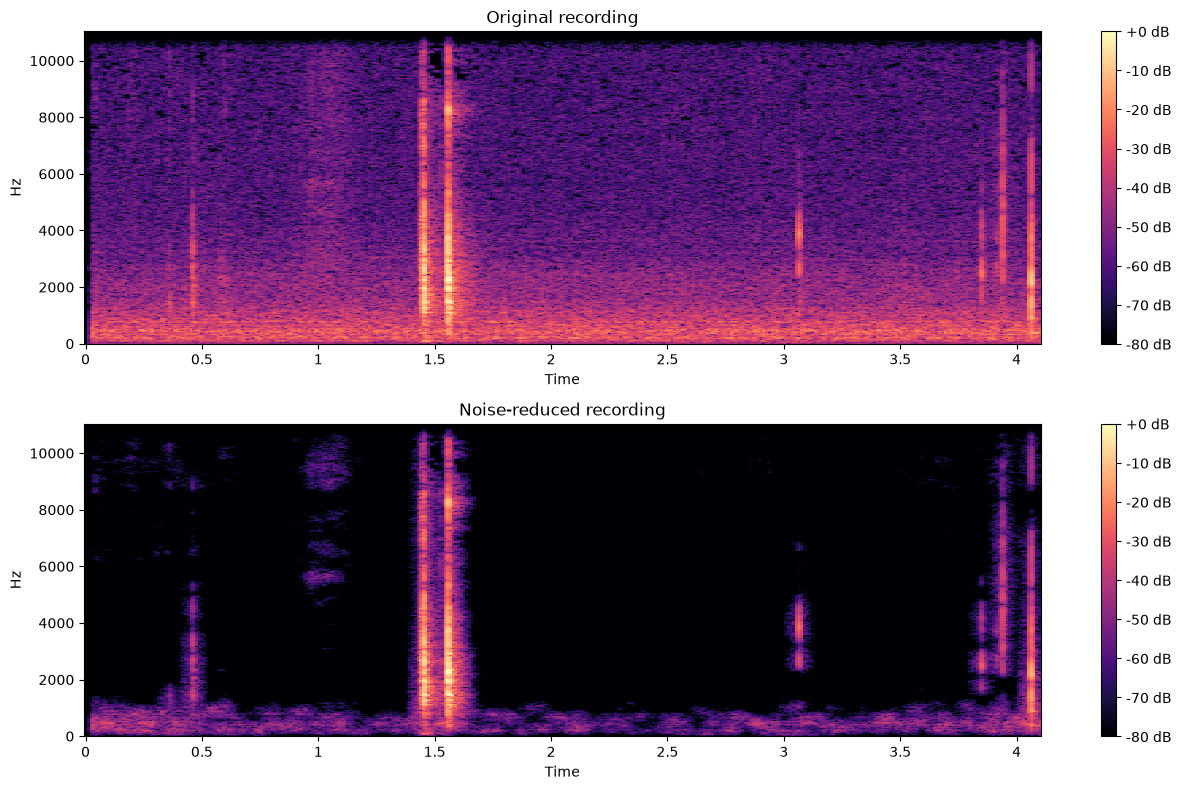

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

for ax, signal, title in [
    (axes[0], y, "Original recording"),
    (axes[1], cleaned, "Noise-reduced recording")
]:
    D = librosa.stft(signal, n_fft=1024, hop_length=256)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    img = librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=256,
        x_axis="time",
        y_axis="hz",
        cmap="magma",
        ax=ax
    )
    ax.set_title(title)
    fig.colorbar(img, ax=ax, format="%+2.0f dB")

plt.tight_layout()
plt.show()

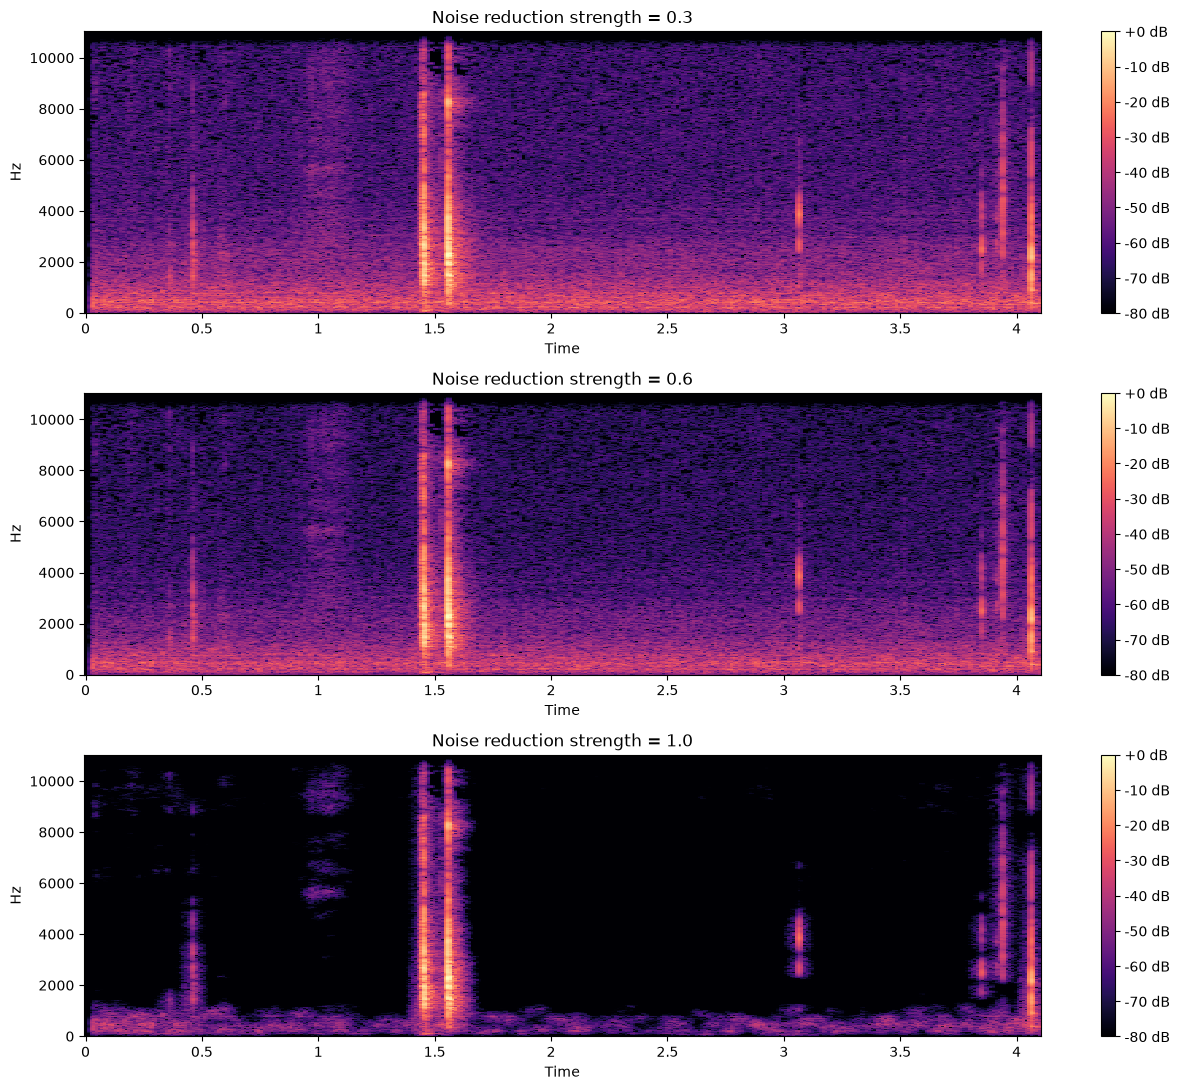

In [ ]:
settings = [0.3, 0.6, 1.0]
results = {}

for strength in settings:
    results[strength] = nr.reduce_noise(
        y=y,
        sr=sr,
        y_noise=noise_sample,
        prop_decrease=strength
    )

fig, axes = plt.subplots(3, 1, figsize=(13, 11))

for ax, strength in zip(axes, settings):
    D = librosa.stft(
        results[strength],
        n_fft=1024,
        hop_length=256
    )
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    img = librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=256,
        x_axis="time",
        y_axis="hz",
        cmap="magma",
        ax=ax
    )

    ax.set_title(f"Noise reduction strength = {strength}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")

plt.tight_layout()
plt.show()

Clip duration: 0.50 seconds


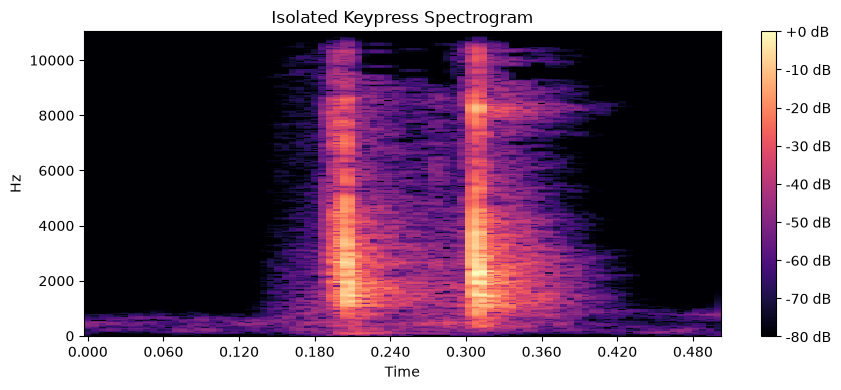

In [ ]:
key_time = 1.50
window_before = 0.25
window_after = 0.25

start = int((key_time - window_before) * sr)
end = int((key_time + window_after) * sr)

keypress = cleaned[start:end]

# Save the isolated keypress
sf.write("./dataset/detected/", keypress, sr)

print(f"Clip duration: {len(keypress) / sr:.2f} seconds")

# Plot its spectrogram
D = librosa.stft(keypress, n_fft=512, hop_length=128)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(9, 4))
librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=128,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Isolated Keypress Spectrogram")
plt.tight_layout()
plt.show()

Duration: 4.10 seconds
Sample rate: 40000 Hz

Detected 1 sound event(s).
1. dataset\detected\event_001.wav | 0.45 seconds


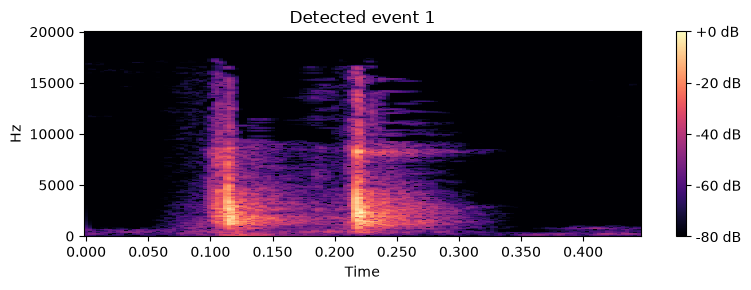


Listen to the extracted clips to verify detection.
Event 1


In [34]:
import numpy as np
import librosa
import soundfile as sf
import noisereduce as nr
import matplotlib.pyplot as plt
import librosa.display

from pathlib import Path
from IPython.display import Audio, display

# ---------- CONFIGURATION ----------
AUDIO_FILE = "./data/Q.mp3"
SAMPLE_RATE = 40000

NOISE_SECONDS = 0.8       # Initial section used to estimate background noise
NOISE_REDUCTION = 1
PRE_ROLL = 0.10           # Audio kept before each event
POST_ROLL = 0.18          # Audio kept after each event
MERGE_GAP = 0.12          # Merge bursts separated by <= this duration
MIN_EVENT_DURATION = 0.025
THRESHOLD_MULTIPLIER = 3.0

OUTPUT_DIR = Path("dataset/detected")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------- 1. LOAD AUDIO ----------
y, sr = librosa.load(
    AUDIO_FILE,
    sr=SAMPLE_RATE,
    mono=True
)

print(f"Duration: {len(y) / sr:.2f} seconds")
print(f"Sample rate: {sr} Hz")

# ---------- 2. ESTIMATE NOISE AND DENOISE ----------
noise_end = min(int(NOISE_SECONDS * sr), len(y))
noise_sample = y[:noise_end]

cleaned = nr.reduce_noise(
    y=y,
    sr=sr,
    y_noise=noise_sample,
    prop_decrease=NOISE_REDUCTION
)

# ---------- 3. CALCULATE SHORT-TIME ENERGY ----------
frame_length = 512
hop_length = 128

rms = librosa.feature.rms(
    y=cleaned,
    frame_length=frame_length,
    hop_length=hop_length,
    center=True
)[0]

times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=hop_length
)

# Estimate the quieter background level robustly
noise_level = np.percentile(rms, 40)
peak_level = np.max(rms)

threshold = max(
    noise_level * THRESHOLD_MULTIPLIER,
    peak_level * 0.04
)

active = rms > threshold

# ---------- 4. MERGE SHORT GAPS ----------
# This allows a key's downstroke and release to form one event.
max_gap_frames = max(1, int(MERGE_GAP * sr / hop_length))
active = active.copy()

i = 0
while i < len(active):
    if active[i]:
        i += 1
        continue

    j = i
    while j < len(active) and not active[j]:
        j += 1

    if (
        i > 0
        and j < len(active)
        and j - i <= max_gap_frames
    ):
        active[i:j] = True

    i = j

# ---------- 5. FIND EVENT BOUNDARIES ----------
changes = np.diff(
    np.r_[False, active, False].astype(int)
)

starts = np.where(changes == 1)[0]
ends = np.where(changes == -1)[0]

events = []

for start_frame, end_frame in zip(starts, ends):
    start_time = max(0, times[start_frame])
    end_time = min(len(y) / sr, times[end_frame - 1])

    if end_time - start_time < MIN_EVENT_DURATION:
        continue

    # Add context before and after the detected sound
    start_sample = max(
        0, int((start_time - PRE_ROLL) * sr)
    )
    end_sample = min(
        len(cleaned), int((end_time + POST_ROLL) * sr)
    )

    clip = cleaned[start_sample:end_sample]

    if len(clip) == 0:
        continue

    events.append({
        "start": start_sample / sr,
        "end": end_sample / sr,
        "audio": clip
    })

# ---------- 6. SAVE AND DISPLAY EVENTS ----------
print(f"\nDetected {len(events)} sound event(s).")

for index, event in enumerate(events, start=1):
    filename = OUTPUT_DIR / f"event_{index:03d}.wav"

    sf.write(filename, event["audio"], sr)

    print(
        f"{index}. {filename} | "
        f"{len(event['audio']) / sr:.2f} seconds"
    )

    # Plot a spectrogram for each detected event
    D = librosa.stft(
        event["audio"],
        n_fft=512,
        hop_length=128
    )

    S_db = librosa.amplitude_to_db(
        np.abs(D),
        ref=np.max
    )

    plt.figure(figsize=(8, 3))
    librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=128,
        x_axis="time",
        y_axis="hz",
        cmap="magma"
    )
    plt.title(f"Detected event {index}")
    plt.colorbar(format="%+2.0f dB")
    plt.tight_layout()
    plt.show()

print("\nListen to the extracted clips to verify detection.")

for index, event in enumerate(events, start=1):
    print(f"Event {index}")
    display(Audio(event["audio"], rate=sr))